# Walkthrough: forecasting indoor CO₂ 15 minutes ahead

This notebook demonstrates the workflow end to end. It contains **no analysis code of its own**: every step calls a function from the `occupancy` package in `src/occupancy/`, where the code is documented and unit-tested. The full experiments are the scripts in `scripts/`; the report is `doc/report/report.md`.

Run it from a fresh clone after `pip install -e ".[dev]"`; it uses the committed processed data in `data/processed/`.

In [1]:
import os
from pathlib import Path

# Work from the repository root so the data paths resolve wherever the notebook is opened.
if Path.cwd().name == "doc":
    os.chdir(Path.cwd().parent)
print("Working directory:", Path.cwd())

Working directory: /home/user/mma3001_final


## 1. Load the data and build the supervised table
Inputs: last hour of CO₂, zone occupancy and time of day. Target: CO₂ in the next 15-minute bin (report Section 2).

In [2]:
from occupancy.co2_regression import NUMERIC_FEATURES_WITH_OCCUPANCY, build_co2_supervised_dataset, building_occupancy_series, co2_series
from occupancy.processed_data import env_readings_raw_or_processed, resampled_occupancy_raw_or_processed

env = env_readings_raw_or_processed("data/raw/5EnvSensor_MayToDec2024_180kRows.csv")
occupancy = building_occupancy_series(resampled_occupancy_raw_or_processed("data/raw/5occupancySensor_MayToDec2024_9MRows.csv"))
table, info = build_co2_supervised_dataset(co2_series(env, "6012002000326", "15min"), occupancy)
features = list(NUMERIC_FEATURES_WITH_OCCUPANCY)
print(info)
table.head()

(raw file not found -- using processed copy data/processed/env_readings.csv.gz)


(raw file not found -- using processed copy data/processed/occupancy_15min.csv.gz)


{'rows_before': 84576, 'rows_after': 17010, 'rows_dropped': 67566, 'pct_dropped': 79.88791146424518}


,time,co2_now,co2_lag1,co2_rolling_1h,building_occupancy,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,target
0,2025-09-11 23:15:00+10:00,451.0,466.0,458.375,0.0,-0.195090,0.980785,0.433884,-0.900969,0.0,445.0
1,2025-09-11 23:30:00+10:00,445.0,451.0,454.375,0.0,-0.130526,0.991445,0.433884,-0.900969,0.0,450.0
2,2025-09-11 23:45:00+10:00,450.0,445.0,453.000,1.0,-0.065403,0.997859,0.433884,-0.900969,0.0,446.0
3,2025-09-12 00:00:00+10:00,446.0,450.0,448.000,0.0,0.000000,1.000000,-0.433884,-0.900969,0.0,444.0
4,2025-09-12 00:15:00+10:00,444.0,446.0,446.250,0.0,0.065403,0.997859,-0.433884,-0.900969,0.0,456.0


## 2. Chronological split and the three key models
Persistence (next = current) is the benchmark; Linear Regression is the interpretable fallback; the tuned SVR is the selected design (report Section 5.4).

In [3]:
import pandas as pd
from occupancy.co2_models import build_linear_regression_pipeline, build_selected_pipeline
from occupancy.evaluation import chronological_split, evaluate_regression_predictions

train, test, cutoff = chronological_split(table, time_col="time", train_frac=0.8)
predictions = {"Persistence": test["co2_now"]}
for name, builder in [("Linear Regression", build_linear_regression_pipeline), ("Selected SVR", build_selected_pipeline)]:
    predictions[name] = builder().fit(train[features], train["target"]).predict(test[features])

pd.DataFrame({name: evaluate_regression_predictions(test["target"], p) for name, p in predictions.items()}).T.round(3)

,mae,rmse,r2,n
Persistence,9.890,29.340,0.155,3402.0
Linear Regression,9.012,25.579,0.358,3402.0
Selected SVR,8.106,25.302,0.372,3402.0


## 3. What the forecast looks like
Two days of the test period. Note that a sudden rise is followed, not anticipated (report Section 5.2).

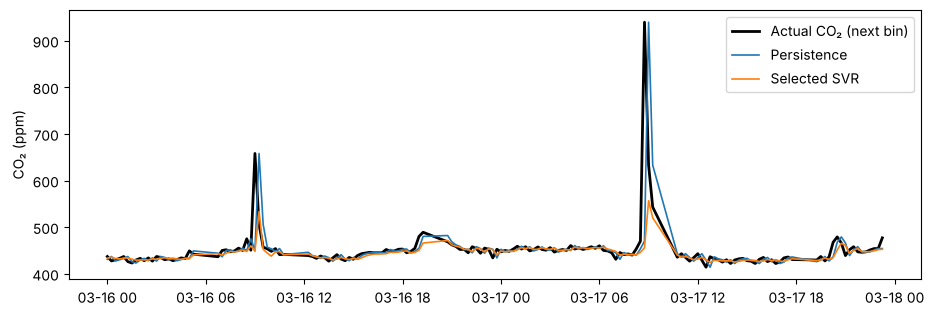

In [4]:
import matplotlib.pyplot as plt

window = test.set_index("time").loc["2026-03-16":"2026-03-17"].index
mask = test["time"].isin(window)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(test.loc[mask, "time"], test.loc[mask, "target"], color="black", lw=2, label="Actual CO₂ (next bin)")
for name in ("Persistence", "Selected SVR"):
    ax.plot(test.loc[mask, "time"], pd.Series(predictions[name], index=test.index)[mask], lw=1.2, label=name)
ax.set_ylabel("CO₂ (ppm)")
ax.legend()
plt.show()

## 4. Input validation
Impossible inputs are rejected; valid inputs outside the training range are flagged as extrapolation (report Section 2.4).

In [5]:
from occupancy.input_validation import extrapolation_warnings, training_ranges, validate_query

print(validate_query(co2_now=-50, co2_lag1=420, co2_rolling_1h=420, building_occupancy=7, hour=25, day_of_week=2))
print(extrapolation_warnings({"co2_now": 1800, "co2_lag1": 1700, "co2_rolling_1h": 1600}, training_ranges(train)))

['co2_now=-50 ppm is outside the valid range 350-5000 ppm', 'building_occupancy=7 must be a whole number from 0 to 5', 'hour=25 must be a whole number from 0 to 23']
['co2_now=1800 ppm is outside the training range 400-1387 ppm (extrapolation: accuracy not validated)', 'co2_lag1=1700 ppm is outside the training range 400-1387 ppm (extrapolation: accuracy not validated)', 'co2_rolling_1h=1600 ppm is outside the training range 402-812 ppm (extrapolation: accuracy not validated)']


## 5. Numerical integration and a physical check
Cumulative exposure with the gap-aware trapezoidal rule, and the ventilation rate fitted to the decay of CO₂ releases (report Sections 3.2 and 4.2).

In [6]:
import numpy as np
from occupancy.co2_integration import trapezoidal_integral_gap_aware
from occupancy.data_quality import spike_decay_rates
from occupancy.env_sensors import pivot_variable

readings = pivot_variable(env, "Carbon dioxide")
readings = readings[readings["sensorid"] == "6012002000326"].sort_values("time")
exposure = trapezoidal_integral_gap_aware(readings["time"], readings["value"], max_gap_hours=2)
print(f"Cumulative exposure: {exposure['total']/1e6:.2f} million ppm·h over {exposure['hours_included']:.0f} h with data")

genuine = readings.drop_duplicates("time").set_index("time")["value"]
genuine = genuine[genuine.index >= pd.Timestamp("2025-09-07", tz=genuine.index.tz)]
rates = spike_decay_rates(genuine)
print(f"{len(rates)} release decays: ventilation rate {np.median(rates):.1f} per hour, time constant {60/np.median(rates):.0f} min")

Cumulative exposure: 2.31 million ppm·h over 5228 h with data
87 release decays: ventilation rate 3.9 per hour, time constant 15 min
